In [1]:
!pip install tensorflow tensorflow_datasets matplotlib seaborn scikit-learn

In [2]:
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras import layers, models, callbacks, optimizers

In [3]:
(ds_train, ds_test), ds_info = tfds.load(
    'malaria',
    split=['train[:80%]', 'train[80%:]'],
    as_supervised=True,
    with_info=True
)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/malaria/incomplete.SXCEEA_1.0.0/malaria-train.tfrecord*...:   0%|         …

Dataset malaria downloaded and prepared to /root/tensorflow_datasets/malaria/1.0.0. Subsequent calls will reuse this data.


In [4]:
IMG_SIZE = 128
BATCH_SIZE = 32

In [5]:
def preprocess(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def augment(image, label):
    image, label = preprocess(image, label)
    image = tf.image.random_flip_left_right(image)
    return image, label

In [6]:
train_ds = ds_train.map(augment).shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = ds_test.map(preprocess).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [7]:
def build_fixed_cnn():
    model = models.Sequential()

    model.add(layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)))

    model.add(layers.Conv2D(32, (3, 3), activation='relu'))
    model.add(layers.MaxPooling2D())

    model.add(layers.Conv2D(64, (3, 3), activation='relu'))
    model.add(layers.MaxPooling2D())

    model.add(layers.Conv2D(128, (3, 3), activation='relu'))
    model.add(layers.MaxPooling2D())

    model.add(layers.Flatten())
    model.add(layers.Dense(64, activation='relu'))
    model.add(layers.Dropout(0.2))
    model.add(layers.Dense(1, activation='sigmoid'))

    return model

In [8]:
model = build_fixed_cnn()

optimizer = optimizers.Adam(learning_rate=0.000005)
model.compile(optimizer=optimizer,
              loss='binary_crossentropy',
              metrics=['accuracy'])

early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=60,
    callbacks=[early_stop]
)


Epoch 1/60
689/689 ━━━━━━━━━━━━━━━━━━━━ 29s 34ms/step - accuracy: 0.5705 - loss: 0.6800 - val_accuracy: 0.6123 - val_loss: 0.6492
Epoch 2/60
689/689 ━━━━━━━━━━━━━━━━━━━━ 21s 29ms/step - accuracy: 0.6483 - loss: 0.6352 - val_accuracy: 0.6656 - val_loss: 0.6180
Epoch 3/60
689/689 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - accuracy: 0.6772 - loss: 0.6072 - val_accuracy: 0.6899 - val_loss: 0.5945
Epoch 4/60
689/689 ━━━━━━━━━━━━━━━━━━━━ 24s 34ms/step - accuracy: 0.6881 - loss: 0.5981 - val_accuracy: 0.6939 - val_loss: 0.5845
Epoch 5/60
689/689 ━━━━━━━━━━━━━━━━━━━━ 23s 33ms/step - accuracy: 0.7011 - loss: 0.5847 - val_accuracy: 0.7037 - val_loss: 0.5749
Epoch 6/60
689/689 ━━━━━━━━━━━━━━━━━━━━ 38s 28ms/step - accuracy: 0.7058 - loss: 0.5775 - val_accuracy: 0.7137 - val_loss: 0.5658
Epoch 7/60
689/689 ━━━━━━━━━━━━━━━━━━━━ 21s 29ms/step - accuracy: 0.7133 - loss: 0.5671 - val_accuracy: 0.7237 - val_loss: 0.5574
Epoch 8/60
689/689 ━━━━━━━━━━━━━━━━━━━━ 40s 28ms/step - accuracy: 0.7200 - loss: 0.5590 - 

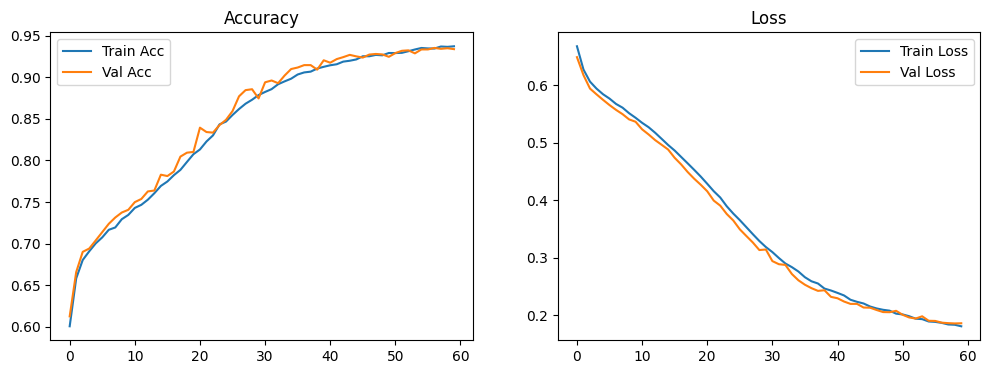

In [9]:
def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Train Acc')
    plt.plot(epochs_range, val_acc, label='Val Acc')
    plt.legend()
    plt.title('Accuracy')

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Train Loss')
    plt.plot(epochs_range, val_loss, label='Val Loss')
    plt.legend()
    plt.title('Loss')
    plt.show()

plot_history(history)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 351ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━

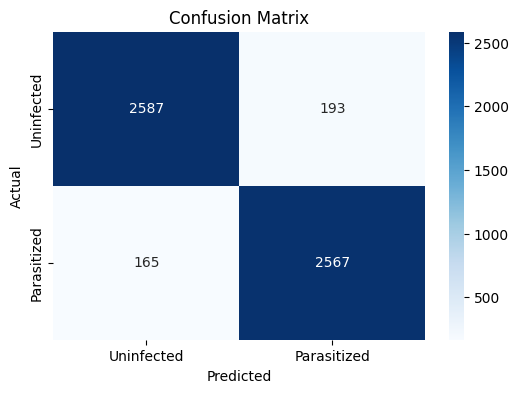

In [10]:
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images)
    y_true.extend(labels.numpy())
    y_pred.extend(np.round(preds).flatten())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=["Uninfected", "Parasitized"]))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Uninfected", "Parasitized"],
            yticklabels=["Uninfected", "Parasitized"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [11]:
model.save("malaria_cnn_model.h5")

In [12]:
from google.colab import files
files.download("malaria_cnn_model.h5")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>